# Exploratory Data Analysis (EDA)

In [6]:
# Use statistical summaries (mean, median, mode,standard deviation)

import pandas as pd
file_path = r"C:\Users\Admin\Downloads\churn-bigml-80.csv"
## loading Dataset
df = pd.read_csv(file_path)
df['Churn_Numeric'] = df['Churn'].astype(int)

In [7]:
import pandas as pd
## Check data types for all columns
print("=== 1. DATA TYPES ===")
print(df.dtypes)

print("\n" + "n"*40 + "\n")


=== 1. DATA TYPES ===
State                         str
Account length              int64
Area code                   int64
International plan            str
Voice mail plan               str
Number vmail messages       int64
Total day minutes         float64
Total day calls             int64
Total day charge          float64
Total eve minutes         float64
Total eve calls             int64
Total eve charge          float64
Total night minutes       float64
Total night calls           int64
Total night charge        float64
Total intl minutes        float64
Total intl calls            int64
Total intl charge         float64
Customer service calls      int64
Churn                        bool
Churn_Numeric               int64
dtype: object

nnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnn



In [8]:
## Check absolute counts of the Churn classes

print("=== 2. CHURN CLASS DISTRIBUTION (COUNTS) ===")
churn_counts = df['Churn'].value_counts()
print(churn_counts)

print("\n" + "n"*48 + "\n")

=== 2. CHURN CLASS DISTRIBUTION (COUNTS) ===
Churn
False    2278
True      388
Name: count, dtype: int64

nnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnnn



In [10]:
## Check percentage distribution to see imbalance severity

print("=== 3. CHURN CLASS DISTRIBUTION (PERCENTAGES) ===")
churn_percentages = df['Churn'].value_counts(normalize=True) * 100
print(churn_percentages)

=== 3. CHURN CLASS DISTRIBUTION (PERCENTAGES) ===
Churn
False    85.446362
True     14.553638
Name: proportion, dtype: float64


In [16]:
## Statistical Summary (Mean, Median, Mode, Std Dev)

num_cols = ['Account length', 'Total day minutes', 'Total day charge', 'Customer service calls']
stats_summary = pd.DataFrame({ 'Mean': df[num_cols].mean(),
                               'Median': df[num_cols].median(),
                               'Mode': df[num_cols].mode().iloc[0],
                               'Std_Dev': df[num_cols].std(),}).round(2)
print('--- STATISTICAL SUMMARY ---\n', stats_summary)
                                                                

--- STATISTICAL SUMMARY ---
                           Mean  Median    Mode  Std_Dev
Account length          100.62  100.00   93.00    39.56
Total day minutes       179.48  179.95  162.30    54.21
Total day charge         30.51   30.59   27.59     9.22
Customer service calls    1.56    1.00    1.00     1.31


In [2]:
## Identify trends, seasonality, snd anomalies

import pandas as pd
df = pd.read_csv(r"C:\Users\Admin\Downloads\churn-bigml-80.csv")
df.columns = df.columns.str.strip()
# Create tenure cohorts and check churn rates
df['Tenure_cohort'] = pd.cut(df['Account length'],
                             bins=[0, 90, 100, 365, 2000],
                             labels=['0-3 Months', '3-6 Months', '6-12 Months', '1+ Years'])

cohort_churn = df.groupby('Tenure_cohort')['Churn'].mean() * 100
print("Churn Rate by Tenure cohort (%):")
print(cohort_churn)

Churn Rate by Tenure cohort (%):
Tenure_cohort
0-3 Months     13.696060
3-6 Months     15.272727
6-12 Months    15.094340
Name: Churn, dtype: float64


In [6]:
# Detecting Anomalies & Outliers
# Detect anomalies in customer service calls' using IQR

Q1 = df['Customer service calls'].quantile(0.25)
Q3 = df['Customer service calls'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter outliers
outliers = df[(df['Customer service calls'] < lower_bound) | (df['Customer service calls'] > upper_bound)]
print(f"Number of statistical anomalies in Customer Service Calls: {len(outliers)}")
print(outliers[['Account length', 'Customer service calls', 'Churn']].head())

Number of statistical anomalies in Customer Service Calls: 210
    Account length  Customer service calls  Churn
12              62                       4  False
18              77                       5   True
45              87                       5   True
58             150                       4   True
65             144                       4   True


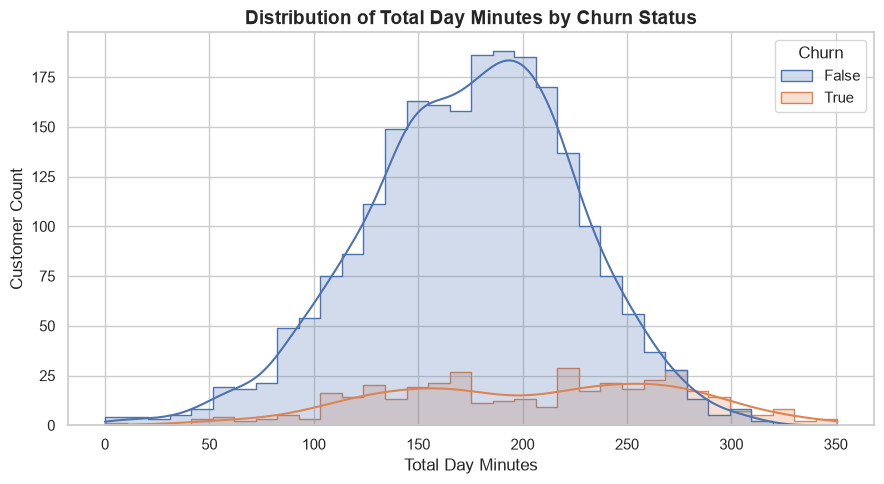

In [12]:
## Data visualization using histograms and scatter plots

import matplotlib.pyplot as plt
import seaborn as sns
# Set virtual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Histogram with explicit parameters
sns.histplot(data=df,
             x="Total day minutes",
             hue="Churn",
             kde=True,
             color="set2",
             element="step")

plt.title('Distribution of Total Day Minutes by Churn Status', fontsize=14, fontweight='bold')
plt.xlabel('Total Day Minutes', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)

plt.tight_layout()
plt.show()

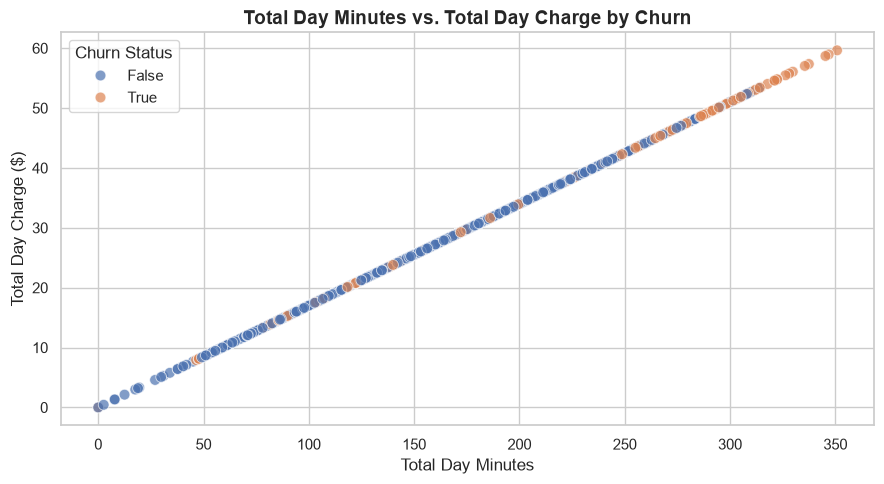

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

# Scatter plot with explicit parameters and transparency (alpha) to see overlapping
sns.scatterplot(
    data=df,
    x="Total day minutes",
    y="Total day charge",
    hue="Churn",
    color="set2",
    alpha=0.7,
    s=60
)

plt.title('Total Day Minutes vs. Total Day Charge by Churn', fontsize=14, fontweight='bold')
plt.xlabel('Total Day Minutes', fontsize=12)
plt.ylabel('Total Day Charge ($)', fontsize=12)

plt.legend(title='Churn Status')
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

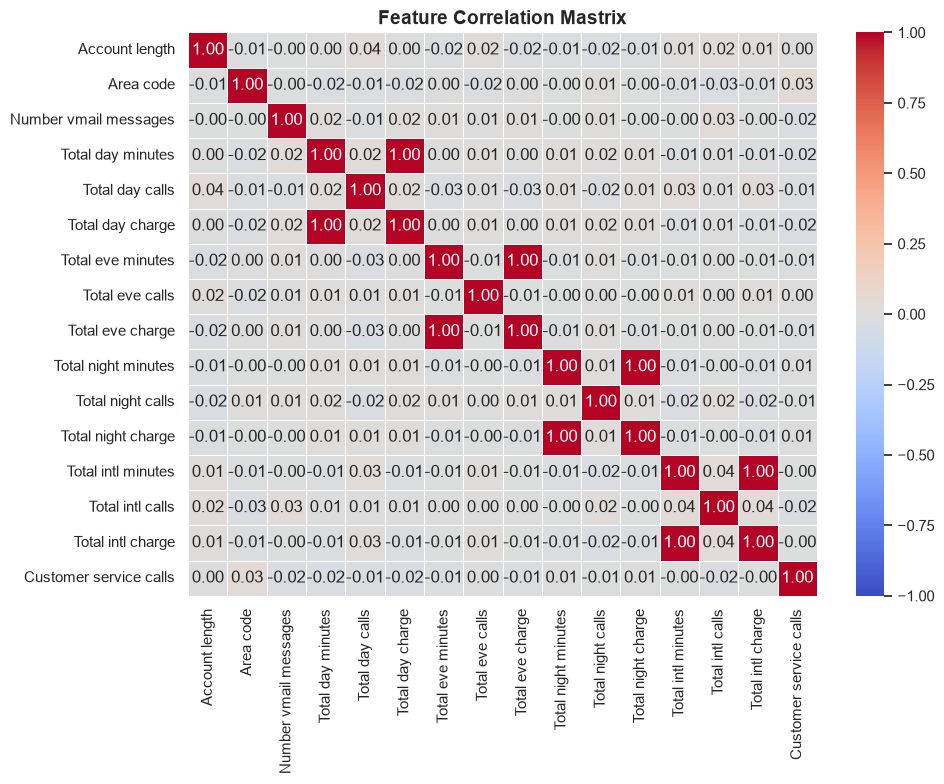

In [18]:
## Using Correlation and Regression analysis for insight

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

# Select only numeric columns for correlation
numeric_df = df.select_dtypes(include=['float64', 'int64', 'int32'])
corr_matrix = numeric_df.corr()

# Plot correlation heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Feature Correlation Mastrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show

In [27]:
# Logistic Regression (Quantifying Churn Drivers)

import statsmodels.api as sm

# 1. Ensure the target variable ('Churn') is numeric (1 for True/Churned, 0 for False
# If Churn is boolean or string, convert it:
if df['Churn'].dtype == 'object':
    df['Churn_binary'] = df['Churn'].map({True: 1, False: 0, 'True': 1, 'False': 0,})
elif df['Churn'].dtype == bool:
    df['Churn_binary'] = df['Churn'].astype(int)
else:
    df['Churn_binary'] = df['Churn']

# 2. Select key predictor features
features = ['Account length', 'Customer service calls', 'Total day minutes']
X = sm.add_constant(df[features]) # Add an intercept term
y = df['Churn_binary']

# 3. Fit the logistic regression model
Logit_model = sm.Logit(y, X).fit()

# 4. Print the statistical summary
print(Logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.374473
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:           Churn_binary   No. Observations:                 2666
Model:                          Logit   Df Residuals:                     2662
Method:                           MLE   Df Model:                            3
Date:                Sat, 14 Nov 2026   Pseudo R-squ.:                 0.09741
Time:                        22:52:19   Log-Likelihood:                -998.34
converged:                       True   LL-Null:                       -1106.1
Covariance Type:            nonrobust   LLR p-value:                 1.891e-46
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -4.8618      0.295    -16.471      0.000      -5.440      